# Stories Café: Exploratory Data Analysis

**Dataset:** `data/stories_transactions.csv`, line-level sales for 3 branches, Jan 1 to Jun 30, 2026.

Each row is one product line on an order. `Transaction ID` identifies the order, so one order can span several rows.

**Sections**
1. Setup and loading
2. Data quality
3. Headline KPIs
4. Growth over time
5. When customers come: day of week and hour
6. Branch economics: price, cost and margin
7. Category and product performance
8. Dayparts and order type
9. Customers and loyalty
10. Baskets and cross-sell
11. Discounts and promotions
12. Feature relationships: correlation heatmaps
13. Key findings and business hypotheses

## 1. Setup and loading

In [1]:
from itertools import combinations
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Palette: validated categorical slots 1-3, fixed per branch (color follows the entity, never its rank)
BRANCH_COLORS = {"Harbour": "#2a78d6", "Garden": "#eb6834", "Uptown": "#1baf7a"}
BRANCHES = list(BRANCH_COLORS)
ACCENT, MUTED = "#2a78d6", "#b9b8b3"
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
SEQ = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": False, "lines.linewidth": 2,
})
usd = mtick.StrMethodFormatter("${x:,.0f}")
pct = mtick.PercentFormatter(1.0, decimals=0)

R, GP = "Line Revenue (USD)", "Line Gross Profit (USD)"
raw = pd.read_csv("../data/stories_transactions.csv")
raw.shape

(51177, 14)

In [2]:
raw.head()

,Transaction ID,Date,Time,Branch,Customer ID,Order Type,Product,Category,Quantity,Unit Price (USD),Discount Rate,Unit Cost (USD),Line Revenue (USD),Line Gross Profit (USD)
0,SYN-0000001,2026-01-01,22:37:35,Harbour,C01797,Takeaway,Fresh Orange Juice,Cold Drinks,1,6.04,0.00,2.12,6.04,3.92
1,SYN-0000002,2026-01-01,17:34:07,Garden,NaN,Dine-in,Egg Sandwich,Breakfast,1,8.15,0.00,4.45,8.15,3.70
2,SYN-0000003,2026-01-01,22:45:29,Harbour,NaN,Dine-in,Brownie,Desserts,1,5.41,0.00,2.37,5.41,3.04
3,SYN-0000004,2026-01-01,21:36:38,Uptown,NaN,Dine-in,Iced Mocha,Cold Coffee,1,6.00,0.00,2.14,6.00,3.86
4,SYN-0000005,2026-01-01,12:34:01,Harbour,C01616,Dine-in,Classic Matcha,Matcha & Tea,1,6.77,0.00,2.27,6.77,4.50


## 2. Data quality

In [3]:
checks = {
    "rows": len(raw),
    "distinct Transaction IDs (orders)": raw["Transaction ID"].nunique(),
    "fully duplicated rows": int(raw.duplicated().sum()),
    "missing Customer ID": int(raw["Customer ID"].isna().sum()),
    "missing Customer ID (%)": round(raw["Customer ID"].isna().mean() * 100, 1),
    "date range": f'{raw["Date"].min()} to {raw["Date"].max()}',
    "products / categories": f'{raw["Product"].nunique()} / {raw["Category"].nunique()}',
}
# Arithmetic consistency: revenue = qty x price x (1 - discount); profit = revenue - qty x cost
rev_calc = raw["Quantity"] * raw["Unit Price (USD)"] * (1 - raw["Discount Rate"])
gp_calc = raw[R] - raw["Quantity"] * raw["Unit Cost (USD)"]
checks["revenue formula mismatches"] = int((abs(rev_calc - raw[R]) > 0.02).sum())
checks["profit formula mismatches"] = int((abs(gp_calc - raw[GP]) > 0.02).sum())
# Order-level fields should not change within an order
g = raw.groupby("Transaction ID")
for c in ["Date", "Time", "Branch", "Customer ID", "Order Type"]:
    checks[f"orders with >1 {c}"] = int((g[c].nunique() > 1).sum())
pd.Series(checks, name="value").to_frame()

,value
rows,51177
distinct Transaction IDs (orders),33887
fully duplicated rows,132
missing Customer ID,18691
missing Customer ID (%),36.50
date range,2026-01-01 to 2026-06-30
products / categories,45 / 9
revenue formula mismatches,0
profit formula mismatches,0
orders with >1 Date,0


In [4]:
# The duplicates are identical lines inside the same order (same product, time and price).
raw[raw.duplicated(keep=False)].head(6)

,Transaction ID,Date,Time,Branch,Customer ID,Order Type,Product,Category,Quantity,Unit Price (USD),Discount Rate,Unit Cost (USD),Line Revenue (USD),Line Gross Profit (USD)
204,SYN-0000142,2026-01-01,19:47:18,Garden,C03183,Dine-in,Iced Matcha,Matcha & Tea,1,6.85,0.00,3.59,6.85,3.26
205,SYN-0000142,2026-01-01,19:47:18,Garden,C03183,Dine-in,Iced Matcha,Matcha & Tea,1,6.85,0.00,3.59,6.85,3.26
898,SYN-0000599,2026-01-05,11:03:56,Harbour,NaN,Takeaway,Turkey & Cheese Sandwich,Sandwiches,1,10.13,0.00,4.72,10.13,5.41
900,SYN-0000599,2026-01-05,11:03:56,Harbour,NaN,Takeaway,Turkey & Cheese Sandwich,Sandwiches,1,10.13,0.00,4.72,10.13,5.41
1019,SYN-0000685,2026-01-06,15:43:36,Garden,C01682,Takeaway,Espresso,Hot Coffee,1,2.65,0.00,0.93,2.65,1.72
1020,SYN-0000685,2026-01-06,15:43:36,Garden,C01682,Takeaway,Espresso,Hot Coffee,1,2.65,0.00,0.93,2.65,1.72


**Data quality notes**
- The data is clean overall: no missing values except `Customer ID`, revenue and profit match their formulas exactly, and order-level fields are consistent within each order.
- **132 fully duplicated lines** (0.3%). We can't tell whether they are double-scans or two separate lines for the same item. **We drop them** in this analysis. The team should agree on this choice.
- **36.5% of lines have no `Customer ID`.** These are walk-in or non-loyalty orders. They are kept for sales analysis and excluded from customer analysis.
- IDs start with `SYN-`, so the data is synthetic and patterns may be cleaner than in real life.

In [5]:
df = raw.drop_duplicates().copy()
df["Date"] = pd.to_datetime(df["Date"])
df["hour"] = pd.to_datetime(df["Time"], format="%H:%M:%S").dt.hour
df["month"] = df["Date"].dt.to_period("M")
df["dow"] = pd.Categorical(df["Date"].dt.day_name(),
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"], ordered=True)
df["daypart"] = pd.cut(df["hour"], [0, 10, 17, 24], right=True, include_lowest=True,
                       labels=["Morning (7-10)", "Afternoon (11-17)", "Evening (18-23)"])
df["known_customer"] = df["Customer ID"].notna()

orders = df.groupby("Transaction ID").agg(
    date=("Date", "first"), hour=("hour", "first"), dow=("dow", "first"), branch=("Branch", "first"),
    order_type=("Order Type", "first"), customer=("Customer ID", "first"),
    revenue=(R, "sum"), profit=(GP, "sum"), items=("Quantity", "sum"), lines=("Product", "size"),
    discount=("Discount Rate", "max"),
)
df.shape, orders.shape

((51045, 19), (33887, 11))

## 3. Headline KPIs

In [6]:
kpi = pd.Series({
    "Revenue": df[R].sum(),
    "Gross profit": df[GP].sum(),
    "Gross margin": df[GP].sum() / df[R].sum(),
    "Orders": len(orders),
    "Average order value": orders["revenue"].mean(),
    "Items per order": orders["items"].mean(),
    "Orders per day (all branches)": len(orders) / df["Date"].nunique(),
})
kpi.to_frame("value")

,value
Revenue,"305,183.71"
Gross profit,"178,994.28"
Gross margin,0.59
Orders,"33,887.00"
Average order value,9.01
Items per order,1.59
Orders per day (all branches),187.22


In [7]:
branch = orders.groupby("branch").agg(revenue=("revenue", "sum"), profit=("profit", "sum"),
                                      orders=("revenue", "size"), aov=("revenue", "mean"))
branch["margin"] = branch["profit"] / branch["revenue"]
branch["orders_per_day"] = branch["orders"] / df["Date"].nunique()
branch["revenue_share"] = branch["revenue"] / branch["revenue"].sum()
branch["profit_share"] = branch["profit"] / branch["profit"].sum()
branch.loc[BRANCHES]

,revenue,profit,orders,aov,margin,orders_per_day,revenue_share,profit_share
branch,,,,,,,,
Harbour,"150,099.05","97,503.46",16334,9.19,0.65,90.24,0.49,0.54
Garden,"99,530.55","46,696.16",11163,8.92,0.47,61.67,0.33,0.26
Uptown,"55,554.11","34,794.66",6390,8.69,0.63,35.30,0.18,0.19


## 4. Growth over time

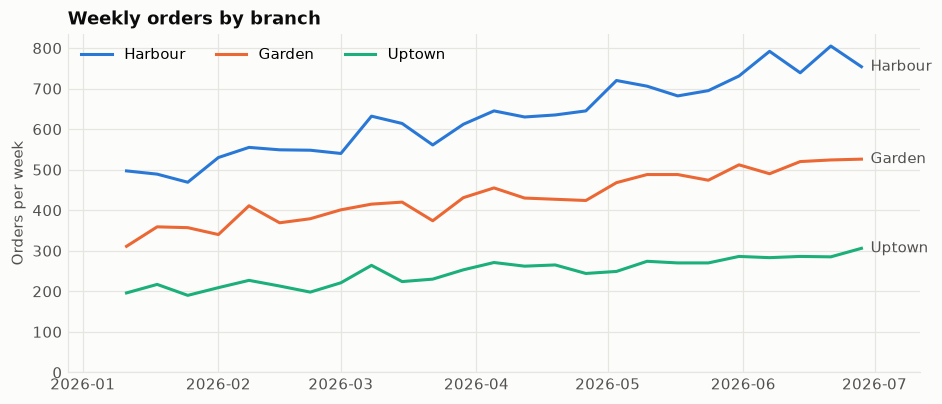

In [8]:
weekly = (orders.set_index("date").groupby("branch").resample("W-SUN")["revenue"].count()
          .unstack(0)[BRANCHES])
weekly = weekly.iloc[1:-1]  # drop partial first and last weeks

fig, ax = plt.subplots(figsize=(10, 4))
for b in BRANCHES:
    ax.plot(weekly.index, weekly[b], color=BRANCH_COLORS[b], label=b)
    ax.annotate(b, (weekly.index[-1], weekly[b].iloc[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", color=INK2)
ax.set_title("Weekly orders by branch")
ax.set_ylabel("Orders per week")
ax.set_ylim(0)
ax.legend(loc="upper left", ncols=3)
ax.margins(x=0.08)
plt.show()

In [9]:
monthly = orders.groupby([orders["date"].dt.to_period("M"), "branch"]).agg(
    revenue=("revenue", "sum"), orders=("revenue", "size"), aov=("revenue", "mean")).unstack()
growth = (monthly.loc[monthly.index[-1]] / monthly.loc[monthly.index[0]] - 1).unstack(0)
print("Jan to Jun change by branch")
growth[["revenue", "orders", "aov"]].loc[BRANCHES].style.format("{:+.1%}")

Jan to Jun change by branch


,revenue,orders,aov
branch,,,
Harbour,+56.9%,+54.9%,+1.3%
Garden,+49.1%,+50.4%,-0.8%
Uptown,+46.2%,+47.2%,-0.7%


**Takeaway:** orders grew about **50% from January to June** in all three branches, with a step up in March. **Average order value stayed flat at about $9.** All of the growth came from more orders, none from bigger baskets, so raising basket size is still untapped.

## 5. When customers come: day of week and hour

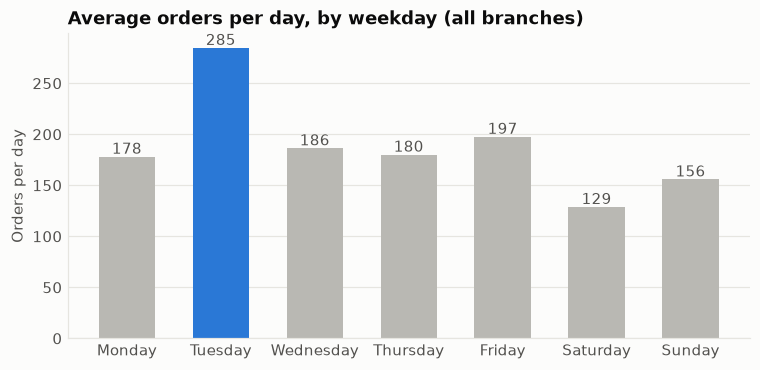

In [10]:
days_per_dow = df.groupby("dow", observed=True)["Date"].nunique()
dow_avg = orders.groupby("dow", observed=True).size() / days_per_dow

fig, ax = plt.subplots(figsize=(8, 3.6))
colors = [ACCENT if d == dow_avg.idxmax() else MUTED for d in dow_avg.index]
ax.bar(dow_avg.index.astype(str), dow_avg.values, color=colors, width=0.6)
for i, v in enumerate(dow_avg.values):
    ax.text(i, v + 3, f"{v:.0f}", ha="center", color=INK2)
ax.set_title("Average orders per day, by weekday (all branches)")
ax.set_ylabel("Orders per day")
ax.grid(axis="x", visible=False)
plt.show()

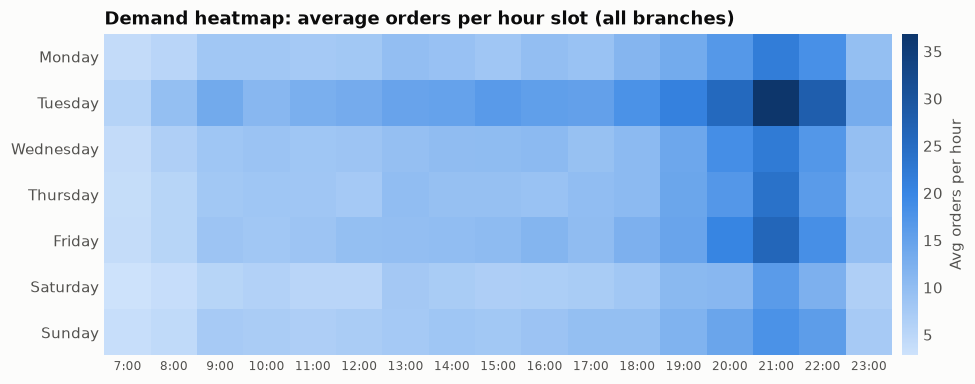

In [11]:
heat = orders.pivot_table(index="dow", columns="hour", values="revenue", aggfunc="size", observed=True)
heat = heat.div(days_per_dow, axis=0)

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("seq", SEQ)
fig, ax = plt.subplots(figsize=(11, 3.8))
im = ax.imshow(heat.values, aspect="auto", cmap=cmap)
ax.set_xticks(range(heat.shape[1]), [f"{h}:00" for h in heat.columns], rotation=0, fontsize=8)
ax.set_yticks(range(heat.shape[0]), heat.index.astype(str))
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, pad=0.01)
cb.set_label("Avg orders per hour", color=INK2)
cb.outline.set_visible(False)
ax.set_title("Demand heatmap: average orders per hour slot (all branches)")
plt.show()

**Takeaways**
- **Tuesday is the busiest day by far**, about 55% above other weekdays. All of the 15 busiest days are Tuesdays. Something recurring, such as a promotion, event or local traffic pattern, is driving it. The team should find out what it is and whether it can be repeated on other days.
- **Weekends are the weakest days**, and Saturday is the lowest. That's unusual for a café and a clear opportunity, for example weekend brunch or family offers.
- **Demand is concentrated in the evening.** It peaks at **21:00**, and 19:00 to 22:00 carries a large share of the day. This café behaves more like an evening hangout than a morning coffee stop.

## 6. Branch economics: price, cost and margin

In [12]:
unit = df.groupby(["Product", "Branch"])[["Unit Price (USD)", "Unit Cost (USD)"]].first().unstack()
price_idx = unit["Unit Price (USD)"].div(unit["Unit Price (USD)"]["Harbour"], axis=0)
cost_idx = unit["Unit Cost (USD)"].div(unit["Unit Cost (USD)"]["Harbour"], axis=0)
pd.DataFrame({"price vs Harbour": price_idx.mean(), "unit cost vs Harbour": cost_idx.mean(),
              "gross margin": branch["margin"]}).loc[BRANCHES].style.format("{:.0%}")

,price vs Harbour,unit cost vs Harbour,gross margin
Harbour,100%,100%,65%
Garden,95%,143%,47%
Uptown,91%,96%,63%


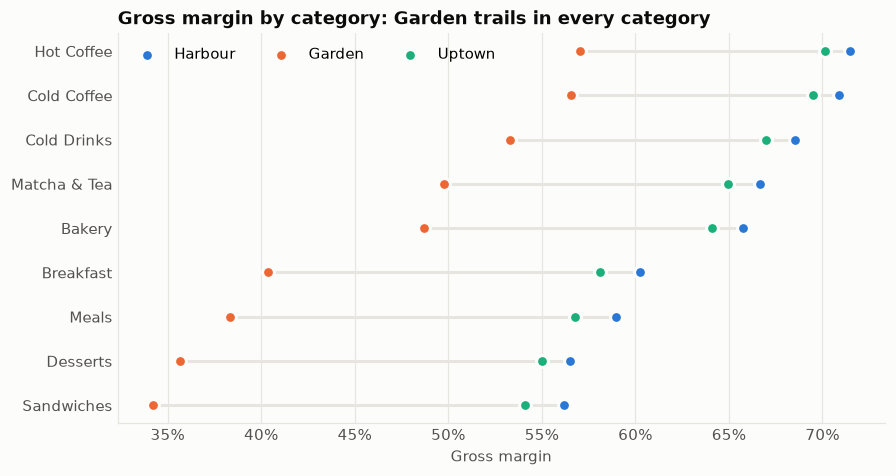

In [13]:
cat_margin = (df.pivot_table(index="Category", columns="Branch", values=GP, aggfunc="sum")
              / df.pivot_table(index="Category", columns="Branch", values=R, aggfunc="sum"))[BRANCHES]
cat_margin = cat_margin.sort_values("Harbour")

fig, ax = plt.subplots(figsize=(9, 4.6))
y = np.arange(len(cat_margin))
for b in BRANCHES:
    ax.scatter(cat_margin[b], y, s=60, color=BRANCH_COLORS[b], label=b, zorder=3,
               edgecolors=SURFACE, linewidths=2)
ax.hlines(y, cat_margin.min(axis=1), cat_margin.max(axis=1), color=GRID, lw=2, zorder=2)
ax.set_yticks(y, cat_margin.index)
ax.xaxis.set_major_formatter(pct)
ax.set_xlabel("Gross margin")
ax.set_title("Gross margin by category: Garden trails in every category")
ax.legend(loc="upper left", ncols=3)
ax.grid(axis="y", visible=False)
plt.show()

In [14]:
# What Garden would have earned at Harbour's cost base (same prices and volumes)
g = df[df["Branch"] == "Garden"]
garden_cost_actual = (g["Quantity"] * g["Unit Cost (USD)"]).sum()
garden_cost_at_harbour = (g["Quantity"] * g["Product"].map(unit["Unit Cost (USD)"]["Harbour"])).sum()
print(f"Garden COGS over 6 months:            ${garden_cost_actual:,.0f}")
print(f"Same items at Harbour unit costs:      ${garden_cost_at_harbour:,.0f}")
print(f"Profit gap from cost base (6 months):  ${garden_cost_actual - garden_cost_at_harbour:,.0f}")

Garden COGS over 6 months:            $52,834
Same items at Harbour unit costs:      $36,947
Profit gap from cost base (6 months):  $15,888


**Takeaway: this is the biggest single finding.** Garden pays about **43% more per unit** than Harbour for every one of the 45 products, yet charges about **5% less**. Its gross margin is **47%**, compared with **65%** at Harbour and **63%** at Uptown. Matching Harbour's cost base would have added about **$16k of gross profit** in six months. Possible causes are supplier contracts, waste, or rent and overhead booked into COGS. The team should find out which.

## 7. Category and product performance

In [15]:
cat = df.groupby("Category").agg(revenue=(R, "sum"), profit=(GP, "sum"), units=("Quantity", "sum"))
cat["margin"] = cat["profit"] / cat["revenue"]
cat["revenue_share"] = cat["revenue"] / cat["revenue"].sum()
cat.sort_values("profit", ascending=False)

,revenue,profit,units,margin,revenue_share
Category,,,,,
Matcha & Tea,"50,160.03","30,554.71",7977,0.61,0.16
Bakery,"47,874.27","28,790.12",11645,0.60,0.16
Cold Coffee,"41,059.42","27,154.19",7722,0.66,0.13
Hot Coffee,"39,788.15","26,518.86",8581,0.67,0.13
Sandwiches,"38,814.96","19,087.26",3899,0.49,0.13
Desserts,"28,676.00","13,672.72",4675,0.48,0.09
Cold Drinks,"21,342.05","13,498.68",5481,0.63,0.07
Breakfast,"21,364.71","11,377.20",2472,0.53,0.07
Meals,"16,104.12","8,340.54",1503,0.52,0.05


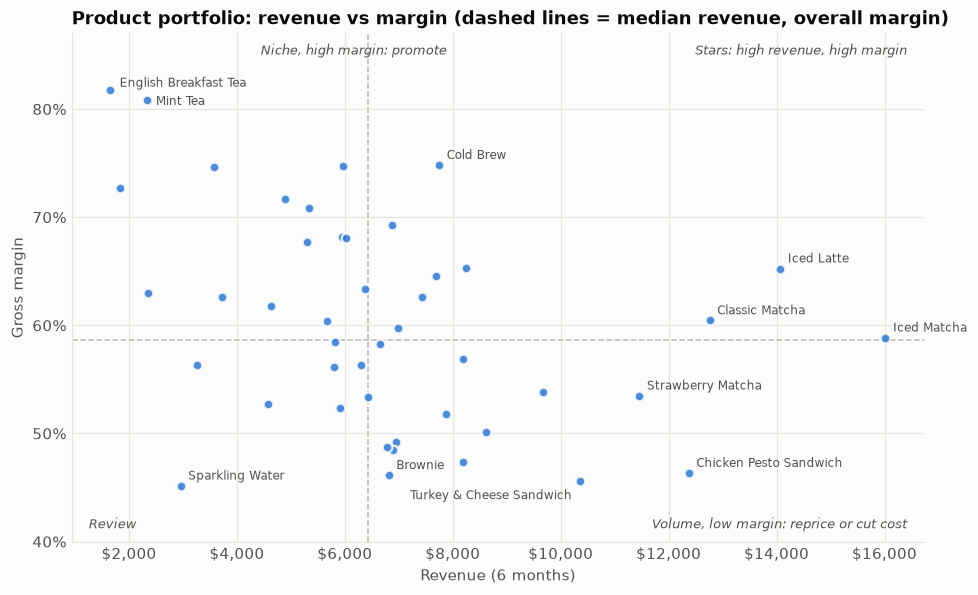

In [16]:
prod = df.groupby(["Product", "Category"]).agg(revenue=(R, "sum"), profit=(GP, "sum"),
                                                units=("Quantity", "sum")).reset_index()
prod["margin"] = prod["profit"] / prod["revenue"]

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(prod["revenue"], prod["margin"], s=40, color=ACCENT, alpha=0.85,
           edgecolors=SURFACE, linewidths=1.5, zorder=3)
mr, mm = prod["revenue"].median(), df[GP].sum() / df[R].sum()
ax.axvline(mr, color=MUTED, lw=1, ls="--")
ax.axhline(mm, color=MUTED, lw=1, ls="--")
label = pd.concat([prod.nlargest(5, "revenue"), prod.nsmallest(4, "margin"), prod.nlargest(3, "margin")]).drop_duplicates("Product")
nudge = {"Turkey & Cheese Sandwich": (-5, -12, "right"), "Mint Tea": (6, -3, "left"),
         "English Breakfast Tea": (6, 2, "left")}
for _, r in label.iterrows():
    dx, dy, ha = nudge.get(r["Product"], (5, 4, "left"))
    ax.annotate(r["Product"], (r["revenue"], r["margin"]), xytext=(dx, dy), textcoords="offset points",
                fontsize=8, color=INK2, ha=ha)
ax.set_ylim(0.40, 0.87)
ax.xaxis.set_major_formatter(usd)
ax.yaxis.set_major_formatter(pct)
ax.set_xlabel("Revenue (6 months)")
ax.set_ylabel("Gross margin")
ax.set_title("Product portfolio: revenue vs margin (dashed lines = median revenue, overall margin)")
for x, y_, t in [(0.98, 0.98, "Stars: high revenue, high margin"), (0.98, 0.02, "Volume, low margin: reprice or cut cost"),
                 (0.44, 0.98, "Niche, high margin: promote"), (0.02, 0.02, "Review")]:
    ax.text(x, y_, t, transform=ax.transAxes, ha="right" if x > 0.3 else "left",
            va="top" if y_ > 0.5 else "bottom", fontsize=8.5, color=INK2, style="italic")
plt.show()

In [17]:
prod.sort_values("margin")[["Product", "Category", "revenue", "margin"]].head(8)

,Product,Category,revenue,margin
38,Sparkling Water,Cold Drinks,"2,955.82",0.45
43,Turkey & Cheese Sandwich,Sandwiches,"10,347.86",0.46
5,Brownie,Desserts,"6,812.21",0.46
11,Chicken Pesto Sandwich,Sandwiches,"12,373.23",0.46
10,Cheesecake Slice,Desserts,"8,192.75",0.47
24,Frozen Yoghurt Cup,Desserts,"6,886.99",0.49
41,Tiramisu Cup,Desserts,"6,784.05",0.49
12,Chicken Salad Bowl,Meals,"6,942.19",0.49


**Takeaways**
- **Matcha & Tea is the top revenue category (16%).** Iced Matcha and Iced Latte are the two best-selling products.
- **Drinks earn the margin and food earns the volume.** Coffee and tea sit at 61-82% margin. Sandwiches (49%), desserts (48%) and meals (52%) sit lowest.
- **Low-margin, high-revenue items to review:** Chicken Pesto and Turkey & Cheese sandwiches, Strawberry Matcha (54%, well below other matcha drinks), Cheesecake and Brownie.
- **Plain teas and black coffee have the best margins** (Mint Tea 81%, English Breakfast 82%, Cold Brew 75%) but low volume, so they are good candidates for upselling or bundles.

## 8. Dayparts and order type

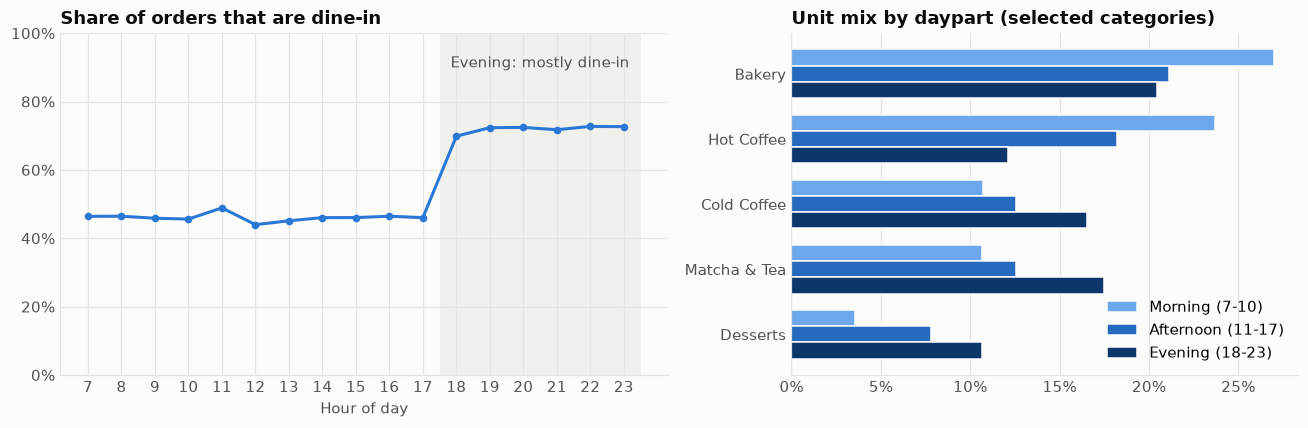

In [18]:
mix = pd.crosstab(df["daypart"], df["Category"], values=df["Quantity"], aggfunc="sum", normalize="index")
ot = pd.crosstab(orders["hour"], orders["order_type"], normalize="index")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
ax.plot(ot.index, ot["Dine-in"], color=ACCENT, marker="o", ms=4)
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0, 1)
ax.set_xticks(ot.index)
ax.set_xlabel("Hour of day")
ax.set_title("Share of orders that are dine-in")
ax.axvspan(17.5, 23.5, color=GRID, alpha=0.5, lw=0)
ax.text(20.5, 0.9, "Evening: mostly dine-in", ha="center", color=INK2)

ax = axes[1]
show = ["Bakery", "Hot Coffee", "Cold Coffee", "Matcha & Tea", "Desserts"]
mix[show].T.plot.barh(ax=ax, color=[SEQ[2], SEQ[4], SEQ[6]], width=0.75, edgecolor=SURFACE, linewidth=1)
ax.xaxis.set_major_formatter(pct)
ax.set_title("Unit mix by daypart (selected categories)")
ax.set_ylabel("")
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.legend(title=None, loc="lower right")
plt.tight_layout()
plt.show()

In [19]:
mix.style.format("{:.0%}")

Category,Bakery,Breakfast,Cold Coffee,Cold Drinks,Desserts,Hot Coffee,Matcha & Tea,Meals,Sandwiches
daypart,,,,,,,,,
Morning (7-10),27%,7%,11%,9%,4%,24%,11%,1%,6%
Afternoon (11-17),21%,5%,13%,11%,8%,18%,13%,3%,8%
Evening (18-23),20%,3%,17%,10%,11%,12%,17%,3%,7%


**Takeaways**
- **Morning and afternoon orders are mostly takeaway (about 54%) and evening orders are mostly dine-in (about 72%).** The evening crowd sits down, which suits table service, desserts and larger orders.
- **The evening mix shifts** toward cold coffee, matcha and desserts, while hot coffee and breakfast drop away.

## 9. Customers and loyalty

In [20]:
known = orders.dropna(subset=["customer"])
cust = known.groupby("customer").agg(orders=("revenue", "size"), spend=("revenue", "sum"),
                                     branches=("branch", "nunique"), first=("date", "min"), last=("date", "max"))
print(f"Identified customers: {len(cust):,}")
print(f"Share of orders from identified customers: {len(known) / len(orders):.1%}")
print(f"Median visits per customer in 6 months: {cust['orders'].median():.0f}")
print(f"Customers who visited 2+ branches: {(cust['branches'] >= 2).mean():.1%}")
top = cust["spend"].sort_values(ascending=False)
print(f"Top 20% of customers' share of identified revenue: {top.head(len(top) // 5).sum() / top.sum():.1%}")
print(f"AOV identified vs anonymous: ${known['revenue'].mean():.2f} vs ${orders[orders['customer'].isna()]['revenue'].mean():.2f}")

Identified customers: 3,494
Share of orders from identified customers: 63.5%
Median visits per customer in 6 months: 6
Customers who visited 2+ branches: 93.8%
Top 20% of customers' share of identified revenue: 33.5%
AOV identified vs anonymous: $9.00 vs $9.02


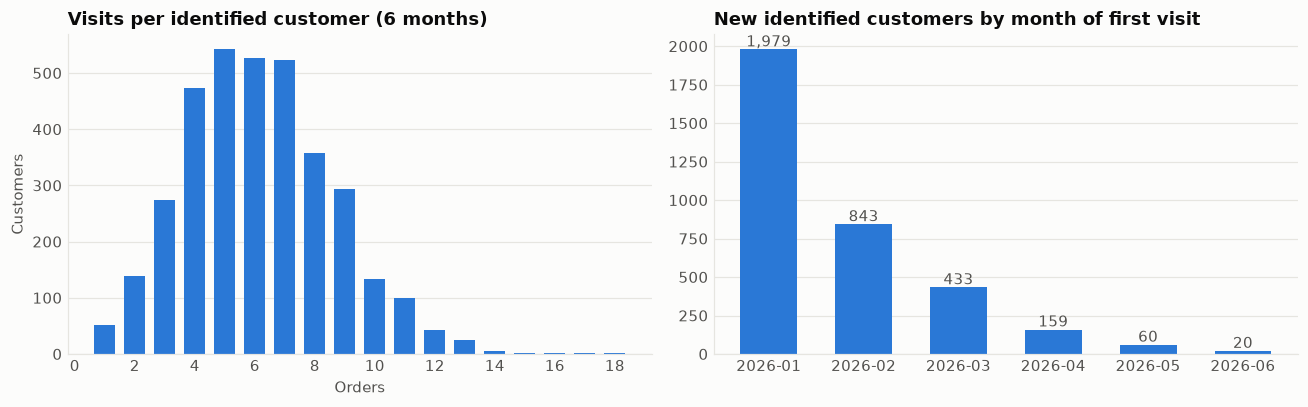

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
vc = cust["orders"].value_counts().sort_index()
axes[0].bar(vc.index, vc.values, color=ACCENT, width=0.7)
axes[0].set_title("Visits per identified customer (6 months)")
axes[0].set_xlabel("Orders")
axes[0].xaxis.set_major_locator(mtick.MaxNLocator(integer=True))
axes[0].set_ylabel("Customers")
axes[0].grid(axis="x", visible=False)

newc = cust["first"].dt.to_period("M").value_counts().sort_index()
axes[1].bar(newc.index.astype(str), newc.values, color=ACCENT, width=0.6)
for i, v in enumerate(newc.values):
    axes[1].text(i, v + 20, f"{v:,}", ha="center", color=INK2)
axes[1].set_title("New identified customers by month of first visit")
axes[1].grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Takeaways**
- About **3,500 identified customers make up 64% of orders.** The median customer visits 6 times in 6 months, and **94% have visited 2 or more branches**, so the brand matters more than any one location.
- Spend is **not very concentrated**: the top 20% of customers bring in 33% of identified revenue. There is no small group of whales.
- **New identified customers drop from about 2,000 in January to 20 in June**, while total orders keep rising. Either growth comes from existing members visiting more and from anonymous walk-ins, or loyalty sign-ups have stalled. *The data is synthetic and may simply have a fixed customer pool, so check this before building a story on it.*

## 10. Baskets and cross-sell

In [22]:
print("Lines per order:")
print(orders["lines"].value_counts(normalize=True).sort_index().map("{:.0%}".format))
basket_cat = df.groupby("Transaction ID")["Category"].apply(lambda s: tuple(sorted(set(s))))
pairs = Counter(p for t in basket_cat for p in combinations(t, 2))
multi = (basket_cat.str.len() >= 2).sum()
pd.DataFrame([(f"{a} + {b}", n, n / multi) for (a, b), n in pairs.most_common(10)],
             columns=["category pair", "orders", "share of multi-category orders"])

Lines per order:
lines
1    54%
2    42%
3     4%
Name: proportion, dtype: str


,category pair,orders,share of multi-category orders
0,Bakery + Matcha & Tea,1994,0.14
1,Bakery + Hot Coffee,1580,0.11
2,Bakery + Cold Coffee,1323,0.09
3,Cold Coffee + Hot Coffee,745,0.05
4,Hot Coffee + Matcha & Tea,729,0.05
5,Cold Coffee + Matcha & Tea,651,0.05
6,Cold Drinks + Hot Coffee,603,0.04
7,Bakery + Cold Drinks,590,0.04
8,Cold Drinks + Sandwiches,532,0.04
9,Bakery + Desserts,530,0.04


In [23]:
basket_prod = df.groupby("Transaction ID")["Product"].apply(lambda s: tuple(sorted(set(s))))
pp = Counter(p for t in basket_prod for p in combinations(t, 2))
pd.DataFrame([(f"{a} + {b}", n) for (a, b), n in pp.most_common(10)], columns=["product pair", "orders"])

,product pair,orders
0,Butter Croissant + Iced Matcha,114
1,Butter Croissant + Classic Matcha,103
2,Butter Croissant + Iced Latte,93
3,Chocolate Cookie + Iced Matcha,89
4,Chocolate Croissant + Iced Matcha,89
5,Iced Matcha + Pistachio Cookie,82
6,Chocolate Cookie + Classic Matcha,76
7,Cinnamon Roll + Classic Matcha,76
8,Chocolate Croissant + Classic Matcha,74
9,Cinnamon Roll + Iced Matcha,73


**Takeaways**
- **54% of orders contain a single line.** That's a large untapped add-on opportunity, given that average order value is flat.
- The natural pairing is **a drink plus a bakery item**. Bakery with Matcha & Tea is the top pair, ahead of Bakery with Hot Coffee. The top product pairs are **Butter Croissant with Iced Matcha or Classic Matcha**, which points to a "matcha + pastry" bundle.

## 11. Discounts and promotions

In [24]:
disc = orders.groupby("discount").agg(orders=("revenue", "size"), aov=("revenue", "mean"),
                                      items=("items", "mean"), margin=("profit", "sum"))
disc["margin"] = disc["margin"] / orders.groupby("discount")["revenue"].sum()
disc["share_of_orders"] = disc["orders"] / disc["orders"].sum()
disc

,orders,aov,items,margin,share_of_orders
discount,,,,,
0.00,30640,8.94,1.57,0.59,0.90
0.10,2789,9.66,1.81,0.56,0.08
0.15,458,9.24,1.78,0.62,0.01


In [25]:
d15 = df[df["Discount Rate"] == 0.15]
print("15% discount: branches", sorted(d15["Branch"].unique()), "| categories", sorted(d15["Category"].unique()))
print("dates:", sorted(d15["Date"].dt.strftime("%b %d").unique()))

15% discount: branches ['Harbour'] | categories ['Cold Coffee', 'Desserts']
dates: ['Mar 12', 'Mar 13', 'Mar 14', 'Mar 15', 'Mar 16', 'Mar 17', 'Mar 18', 'Mar 19', 'May 12', 'May 13', 'May 14', 'May 15', 'May 16', 'May 17', 'May 18', 'May 19']


In [26]:
# Promo weeks (Mar 12-19, May 12-19) vs the rest of those months.
# Garden and Uptown had no 15% promo, so they act as a control group.
pm = df[df["Date"].dt.month.isin([3, 5])].copy()
pm["promo_week"] = pm["Date"].between("2026-03-12", "2026-03-19") | pm["Date"].between("2026-05-12", "2026-05-19")
promo_cats = pm[pm["Category"].isin(["Cold Coffee", "Desserts"])]
units = promo_cats.groupby(["Branch", "promo_week", "Date"])["Quantity"].sum().groupby(["Branch", "promo_week"]).mean().unstack()
profit = pm.groupby(["Branch", "promo_week", "Date"])[GP].sum().groupby(["Branch", "promo_week"]).mean().unstack()
pd.DataFrame({
    "promo-category units/day: lift": units[True] / units[False] - 1,
    "total gross profit/day: lift": profit[True] / profit[False] - 1,
}).loc[BRANCHES].style.format("{:+.1%}")

,promo-category units/day: lift,total gross profit/day: lift
Branch,,
Harbour,+0.7%,-4.0%
Garden,-1.5%,+3.8%
Uptown,-14.5%,-7.1%


**Takeaways**
- **The 10% discount** appears on about 6% of orders at every branch and in every month. It looks like a standing offer, perhaps loyalty or staff. Discounted orders are larger ($9.66 vs $8.94, 1.8 vs 1.6 items), but margin falls to 54%.
- **The 15% promo** ran **only at Harbour**, on **Cold Coffee and Desserts**, for two 8-day windows (Mar 12-19 and May 12-19).
- **No sign the promo drove volume.** Promoted-category units at Harbour were flat (+0.7%) during promo weeks. The profit picture is unclear: Harbour's gross profit per day fell about 4%, but the two branches without the promo moved in opposite directions (Garden +4%, Uptown -7%), so we can't attribute that drop to the promo. *16 days of data, so treat this as directional.*

## 12. Feature relationships: correlation heatmaps

Two heatmaps show how the features move together, one row per product line:
- **Numeric features: Pearson correlation**, from -1 (red: one goes up, the other goes down) through 0 (gray: no straight-line relationship) to +1 (blue: they rise together). Yes/no features are coded as 0/1, and weekday as Monday = 0 to Sunday = 6.
- **Categorical features: Cramér's V**, from 0 (unrelated) to 1 (knowing one tells you the other).

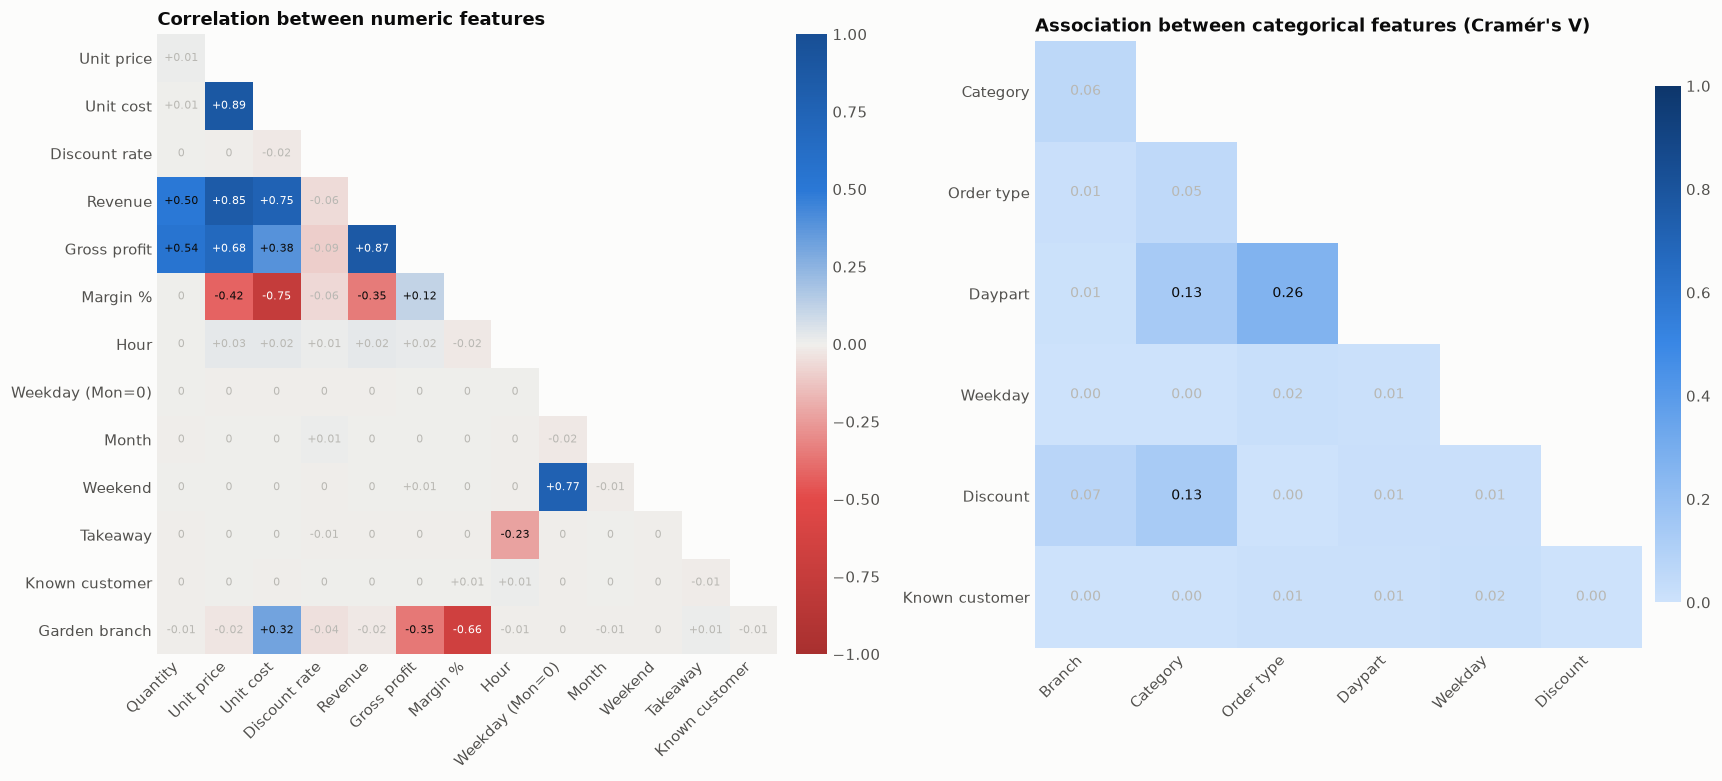

In [27]:
num = pd.DataFrame({
    "Quantity": df["Quantity"],
    "Unit price": df["Unit Price (USD)"],
    "Unit cost": df["Unit Cost (USD)"],
    "Discount rate": df["Discount Rate"],
    "Revenue": df[R],
    "Gross profit": df[GP],
    "Margin %": df[GP] / df[R],
    "Hour": df["hour"],
    "Weekday (Mon=0)": df["Date"].dt.dayofweek,
    "Month": df["Date"].dt.month,
    "Weekend": (df["Date"].dt.dayofweek >= 5).astype(int),
    "Takeaway": (df["Order Type"] == "Takeaway").astype(int),
    "Known customer": df["known_customer"].astype(int),
    "Garden branch": (df["Branch"] == "Garden").astype(int),
})
corr = num.corr()


def cramers_v(a, b):
    """Bias-corrected Cramér's V between two categorical columns."""
    table = pd.crosstab(a, b).to_numpy()
    n = table.sum()
    expected = table.sum(1, keepdims=True) * table.sum(0, keepdims=True) / n
    chi2 = ((table - expected) ** 2 / expected).sum()
    r, k = table.shape
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    r_c, k_c = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / max(1e-12, min(k_c - 1, r_c - 1)))


cat_feats = pd.DataFrame({
    "Branch": df["Branch"],
    "Category": df["Category"],
    "Order type": df["Order Type"],
    "Daypart": df["daypart"].astype(str),
    "Weekday": df["dow"].astype(str),
    "Discount": df["Discount Rate"].astype(str),
    "Known customer": df["known_customer"],
})
cv = pd.DataFrame([[cramers_v(cat_feats[a], cat_feats[b]) for b in cat_feats] for a in cat_feats],
                  index=cat_feats.columns, columns=cat_feats.columns)

# Diverging scale: red (negative) - gray (zero) - blue (positive)
DIV = LinearSegmentedColormap.from_list("div", ["#a8302f", "#e34948", "#f0efec", "#2a78d6", "#184f95"])

fig, axes = plt.subplots(1, 2, figsize=(17, 7.2), gridspec_kw={"width_ratios": [1.45, 1]})
for ax, mat, cmap, vmin, title, fmt in [
    (axes[0], corr, DIV, -1, "Correlation between numeric features", "{:+.2f}"),
    (axes[1], cv, cmap, 0, "Association between categorical features (Cramér's V)", "{:.2f}"),
]:
    # Lower triangle without the diagonal: drop the first row and last column, which would be empty
    shown = mat.where(np.tril(np.ones(mat.shape, dtype=bool), -1)).iloc[1:, :-1]
    im = ax.imshow(shown, cmap=cmap, vmin=vmin, vmax=1)
    n = len(mat)
    ax.set_xticks(range(n - 1), shown.columns, rotation=45, ha="right")
    ax.set_yticks(range(n - 1), shown.index)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    for i in range(n - 1):
        for j in range(i + 1):
            v = shown.iloc[i, j]
            strong = abs(v) >= 0.55
            ax.text(j, i, fmt.format(v).replace("+0.00", "0").replace("-0.00", "0"), ha="center", va="center",
                    fontsize=7.5 if n > 10 else 9, color="white" if strong else (INK if abs(v) >= 0.1 else MUTED))
    cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
    cb.outline.set_visible(False)
    ax.set_title(title)
plt.tight_layout()
plt.show()

In [28]:
# Strongest pairs, excluding each feature with itself
pairs_corr = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
pairs_corr.reindex(pairs_corr.abs().sort_values(ascending=False).index).head(10).rename("correlation").to_frame()

correlation
Unit price      Unit cost             0.89
Revenue         Gross profit          0.87
Unit price      Revenue               0.85
Weekday (Mon=0) Weekend               0.77
Unit cost       Margin %             -0.75
                Revenue               0.75
Unit price      Gross profit          0.68
Margin %        Garden branch        -0.66
Quantity        Gross profit          0.54
                Revenue               0.50

**How to read it**
- **Some pairs are high by construction, not because of an insight.** Price vs revenue, revenue vs gross profit and weekday vs weekend are high because one column is calculated from the other.
- **Garden branch vs Margin %: -0.66.** This is the strongest relationship that isn't built in, and it confirms Garden's cost problem (section 6) from a second angle.
- **Unit cost vs Margin %: -0.75.** Costlier products keep a smaller share of their price. That's why Iced Matcha, the second most expensive drink, has only an average margin.
- **Takeaway vs Hour: -0.23**, and order type vs time of day is 0.26 on the right. Takeaway falls off in the evening (section 8).
- **Category vs Discount: 0.13.** That's the 15% promo, which only applied to Cold Coffee and Desserts (section 11).
- **Discount rate is close to 0 with everything**, so discounts don't go with larger quantities or more profit per line.
- **Limitation:** correlation only measures straight-line relationships. The Tuesday spike (section 5) doesn't show up here, because Tuesday isn't at one end of the Monday-to-Sunday scale.

## 13. Key findings and business hypotheses

| # | Finding | Evidence | Possible business move |
|---|---|---|---|
| 1 | **Garden's cost base is broken** | Unit costs 43% above Harbour on all 45 products; margin 47% vs 65% | Renegotiate suppliers or share Harbour's sourcing; audit waste. Worth about $16k gross profit per 6 months |
| 2 | **Growth comes from order count only** | Orders +50% Jan to Jun; AOV flat at about $9; 54% of orders are single-line | Upsell and bundles: matcha + pastry, coffee + croissant |
| 3 | **Evening is the core business** | Peak at 21:00; 72% dine-in after 18:00; mix shifts to cold drinks, matcha, desserts | Evening menu and staffing; dessert pairing at the table |
| 4 | **Tuesdays boom, weekends lag** | Tuesday about 55% above other weekdays; Saturday lowest | Find the Tuesday driver and replicate it; weekend brunch or family offer |
| 5 | **Food margins are thin** | Sandwiches, desserts and meals at 46-52% vs drinks 61-82% | Reprice or reformulate low-margin top sellers; push high-margin drinks alongside them |
| 6 | **The 15% promo showed no volume lift** | Promoted units flat (+0.7%) at Harbour; profit effect unclear | Test targeted bundles instead of flat discounts |
| 7 | **Customers are brand-loyal, not branch-loyal** | 94% of identified customers use 2+ branches; median 6 visits | Loyalty program built around the brand; personalized offers |

**Open questions for the team:** What is the hackathon brief? Which of these do we build the solution around? Should duplicate lines be dropped?